# Python come supporto allo studio della matematica

Esempi brevi e visuali, in ordine di programma: algebra, retta, parabola, circonferenza, goniometria, trigonometria, esponenziali e logaritmi. Ogni cella di codice si esegue singolarmente (`Shift+Invio`) e può essere modificata per osservare come cambia il risultato.

Librerie usate: **NumPy** (calcolo numerico su array), **Matplotlib** (grafici), **SymPy** (calcolo simbolico), **SciPy** (adattamento di curve a dati).

In [ ]:
%%bash
# 1. controlla estensioni e miniconda
code --list-extensions | grep -i -E "python|jupyter" || echo "estensioni python/jupyter non trovate"
conda --version
conda env list

# 2. installa le estensioni se mancano
code --install-extension ms-python.python
code --install-extension ms-toolsai.jupyter

# 3. crea un ambiente dedicato con tutto il necessario
conda create -n math -c conda-forge python=3.12 numpy pandas matplotlib sympy scipy ipykernel ipywidgets -y

# 4. verifica ("conda activate" non funziona in una cella: si usa "conda run")
conda run -n math python -c "import ipykernel, numpy, sympy, matplotlib; print('ok')"
conda run -n math jupyter kernelspec list || true

# 5. registra il kernel con un nome leggibile
conda run -n math python -m ipykernel install --user --name math --display-name "Python (math)"

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

plt.rcParams.update({"figure.figsize": (6, 4), "axes.grid": True, "font.size": 11})

## 1. Radicali ed equazioni di secondo grado

SymPy lavora con espressioni esatte: i radicali non vengono approssimati.

In [2]:
print(sp.sqrt(72))                       # 6*sqrt(2)
print(sp.radsimp(1 / (1 + sp.sqrt(2))))  # razionalizzazione: -1 + sqrt(2)

6*sqrt(2)
-1 + sqrt(2)


Le soluzioni di $x^2 - 2x - 3 = 0$ sono le ascisse dei punti in cui la parabola $y = x^2 - 2x - 3$ interseca l'asse $x$.

Soluzioni: [-1, 3]
Discriminante: 16


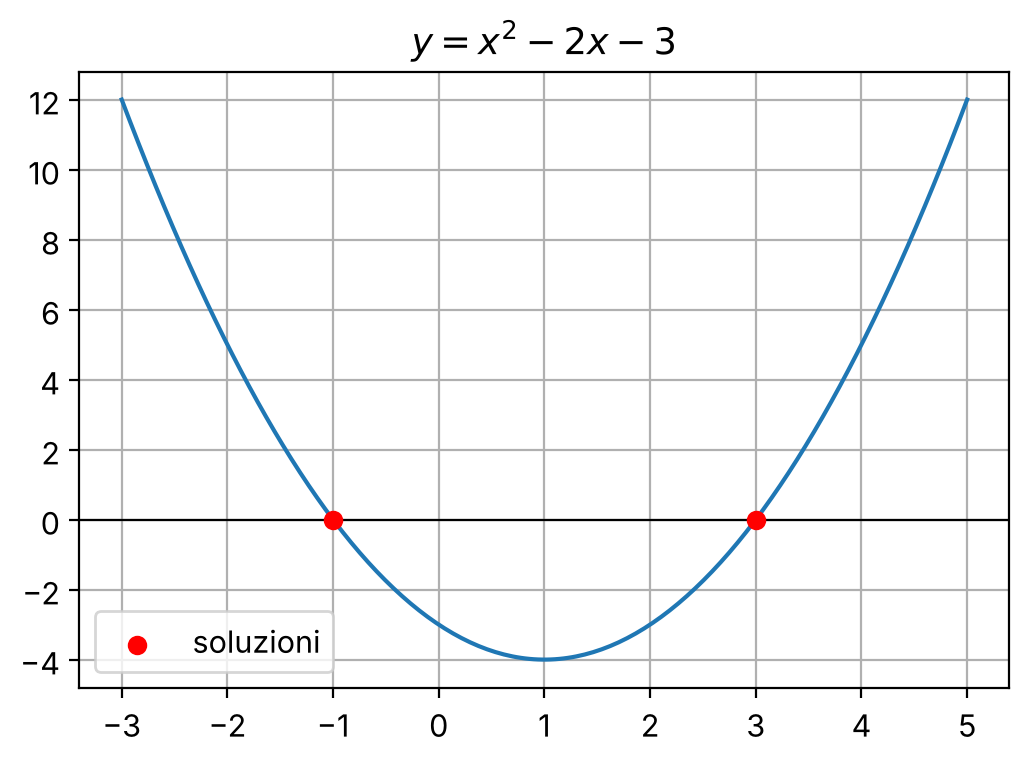

In [3]:
x = sp.symbols("x")
radici = sp.solve(x**2 - 2*x - 3, x)
print("Soluzioni:", radici)
print("Discriminante:", sp.discriminant(x**2 - 2*x - 3, x))

xs = np.linspace(-3, 5, 200)
plt.plot(xs, xs**2 - 2*xs - 3)
plt.scatter([float(r) for r in radici], [0, 0], color="red", zorder=3, label="soluzioni")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("$y = x^2 - 2x - 3$")
plt.legend()
plt.show()

## 2. Sistemi lineari: tre casi

Ogni equazione lineare in due incognite è una retta. La soluzione del sistema è l'insieme dei punti comuni alle due rette.

- rette incidenti: sistema **determinato** (un punto);
- rette parallele distinte: sistema **impossibile** (nessun punto);
- rette coincidenti: sistema **indeterminato** (infiniti punti).

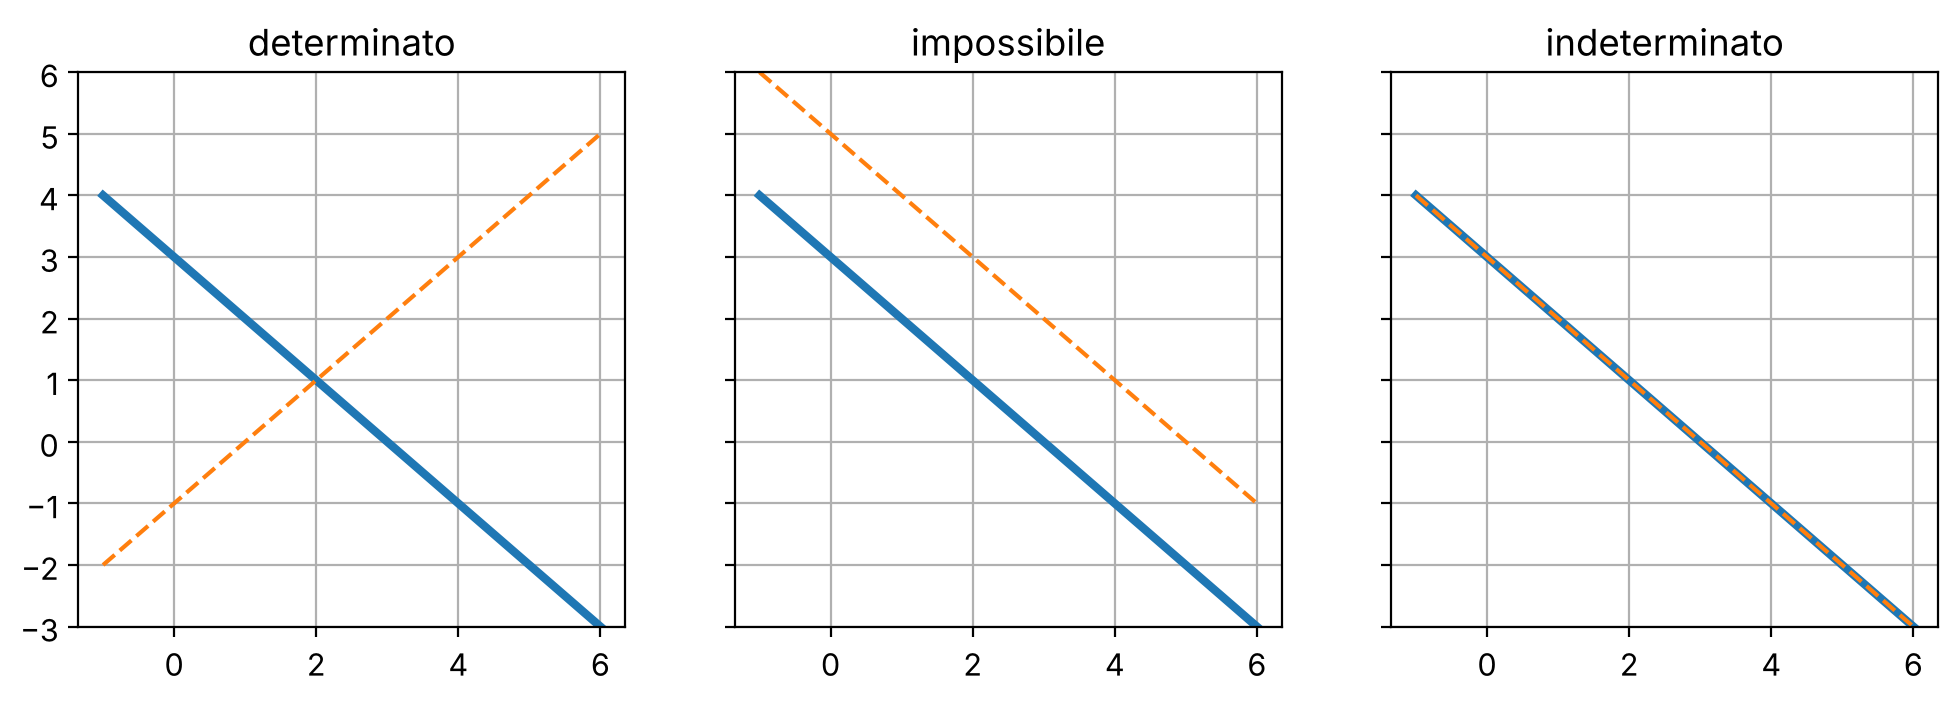

In [4]:
def disegna(ax, a, b, c, **kw):
    xs = np.linspace(-1, 6, 100)
    ax.plot(xs, (c - a*xs) / b, **kw)

sistemi = {
    "determinato": [(1, 1, 3), (1, -1, 1)],
    "impossibile": [(1, 1, 3), (1, 1, 5)],
    "indeterminato": [(1, 1, 3), (2, 2, 6)],
}
fig, assi = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (nome, eqs) in zip(assi, sistemi.items()):
    disegna(ax, *eqs[0], color="tab:blue", linewidth=3)
    disegna(ax, *eqs[1], color="tab:orange", linestyle="--")
    ax.set_title(nome)
    ax.set_ylim(-3, 6)
plt.show()

Regola di Cramer per $\begin{cases} x + y = 3 \\ x - y = 1 \end{cases}$: $x = D_x / D$, $y = D_y / D$ con $D \neq 0$.

In [5]:
D  = sp.Matrix([[1,  1], [1, -1]]).det()
Dx = sp.Matrix([[3,  1], [1, -1]]).det()
Dy = sp.Matrix([[1,  3], [1,  1]]).det()
print("D =", D, " Dx =", Dx, " Dy =", Dy)
print("x =", Dx / D, " y =", Dy / D)

# verifica con SymPy
X, Y = sp.symbols("X Y")
print(sp.solve([X + Y - 3, X - Y - 1], [X, Y]))

D = -2  Dx = -4  Dy = -2
x = 2  y = 1
{X: 2, Y: 1}


## 3. La retta

Retta per due punti $A(1, 2)$ e $B(5, 4)$: coefficiente angolare $m = \dfrac{y_B - y_A}{x_B - x_A}$ e ordinata all'origine $q = y_A - m\,x_A$. Sono rappresentate anche la perpendicolare per $A$ e la distanza di un punto $P$ dalla retta.

m = 0.5,  q = 1.5   ->   y = 0.5x + 1.5
distanza = 3.130


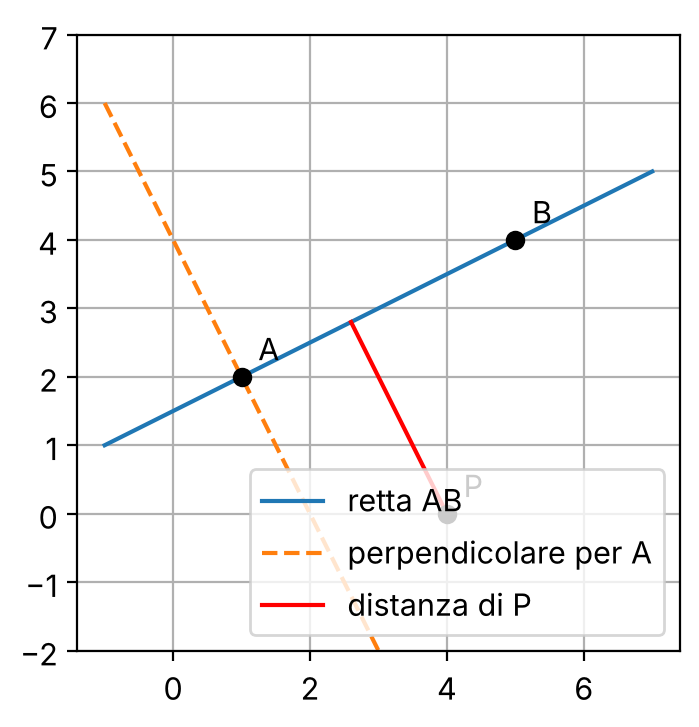

In [6]:
A, B, P = (1, 2), (5, 4), (4, 0)
m = (B[1] - A[1]) / (B[0] - A[0])
q = A[1] - m * A[0]
print(f"m = {m},  q = {q}   ->   y = {m}x + {q}")

# distanza di P dalla retta  m x - y + q = 0
d = abs(m*P[0] - P[1] + q) / np.hypot(m, 1)
# piede della perpendicolare da P
xf = (P[0] + m*(P[1] - q)) / (1 + m**2)
F = (xf, m*xf + q)
print(f"distanza = {d:.3f}")

xs = np.linspace(-1, 7, 100)
plt.plot(xs, m*xs + q, label="retta AB")
plt.plot(xs, A[1] - (xs - A[0]) / m, "--", label="perpendicolare per A")
plt.plot([P[0], F[0]], [P[1], F[1]], color="red", label="distanza di P")
plt.scatter(*zip(A, B, P), color="black", zorder=3)
for nome, pt in zip("ABP", (A, B, P)):
    plt.annotate(nome, pt, textcoords="offset points", xytext=(6, 6))
plt.gca().set_aspect("equal")
plt.ylim(-2, 7)
plt.legend(loc="lower right")
plt.show()

## 4. La parabola

Per $y = ax^2 + bx + c$ il vertice è $V\!\left(-\dfrac{b}{2a},\,-\dfrac{\Delta}{4a}\right)$, il fuoco $F\!\left(-\dfrac{b}{2a},\,\dfrac{1-\Delta}{4a}\right)$, la direttrice $y = -\dfrac{1+\Delta}{4a}$, con $\Delta = b^2 - 4ac$.

vertice (2.0, -1.0)  fuoco (2.0, -0.75)  direttrice y = -1.25


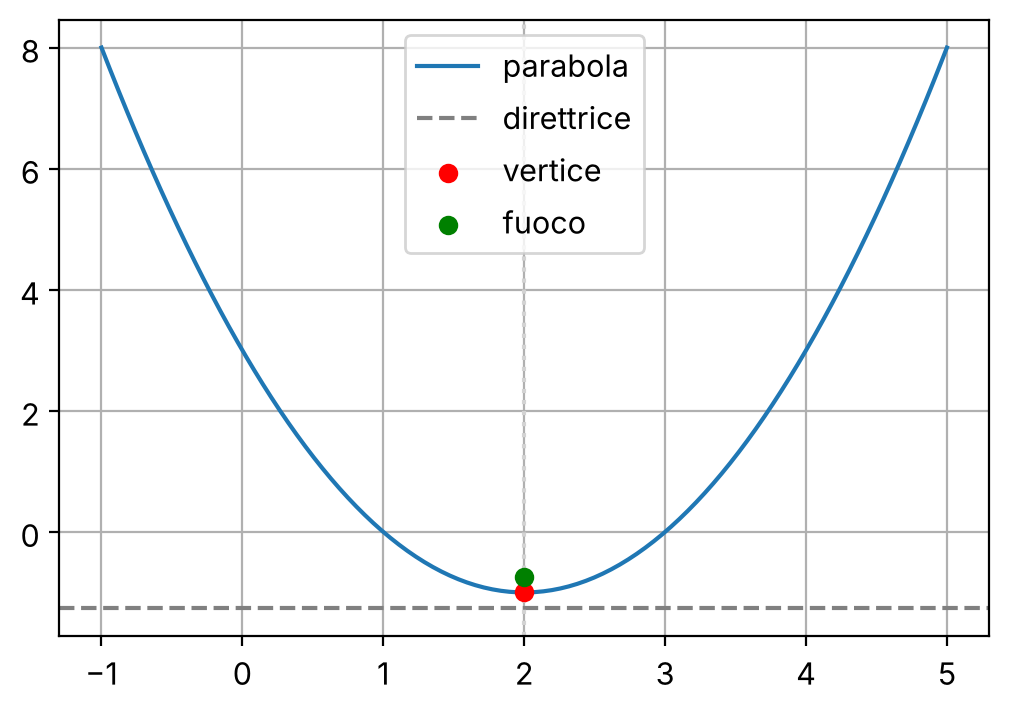

In [7]:
a, b, c = 1, -4, 3
delta = b**2 - 4*a*c
V = (-b/(2*a), -delta/(4*a))
F = (-b/(2*a), (1 - delta)/(4*a))
y_dir = -(1 + delta)/(4*a)
print("vertice", V, " fuoco", F, " direttrice y =", y_dir)

xs = np.linspace(-1, 5, 200)
plt.plot(xs, a*xs**2 + b*xs + c, label="parabola")
plt.axhline(y_dir, color="gray", linestyle="--", label="direttrice")
plt.axvline(V[0], color="lightgray", linestyle=":")
plt.scatter(*V, color="red", zorder=3, label="vertice")
plt.scatter(*F, color="green", zorder=3, label="fuoco")
plt.legend()
plt.show()

Effetto del coefficiente $a$ su $y = ax^2$: segno (concavità) e valore assoluto (apertura).

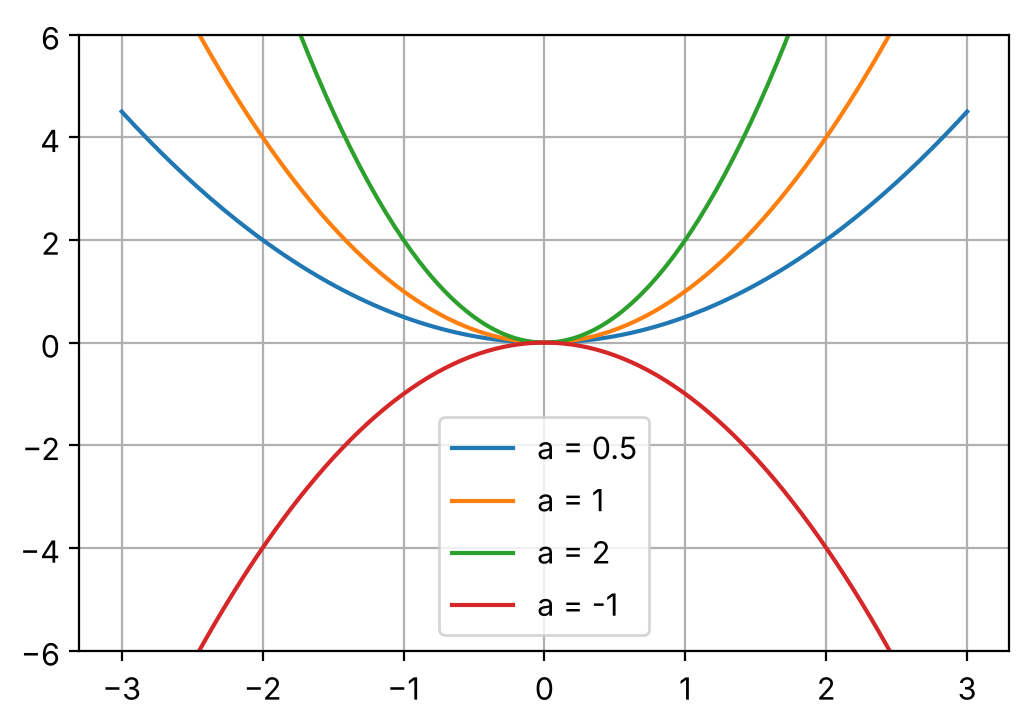

In [8]:
xs = np.linspace(-3, 3, 200)
for a in (0.5, 1, 2, -1):
    plt.plot(xs, a*xs**2, label=f"a = {a}")
plt.ylim(-6, 6)
plt.legend()
plt.show()

Posizione reciproca retta-parabola: il segno del discriminante dell'equazione risolvente decide fra secante, tangente ed esterna. Parabola $y = x^2$ e rette $y = 2x + q$.

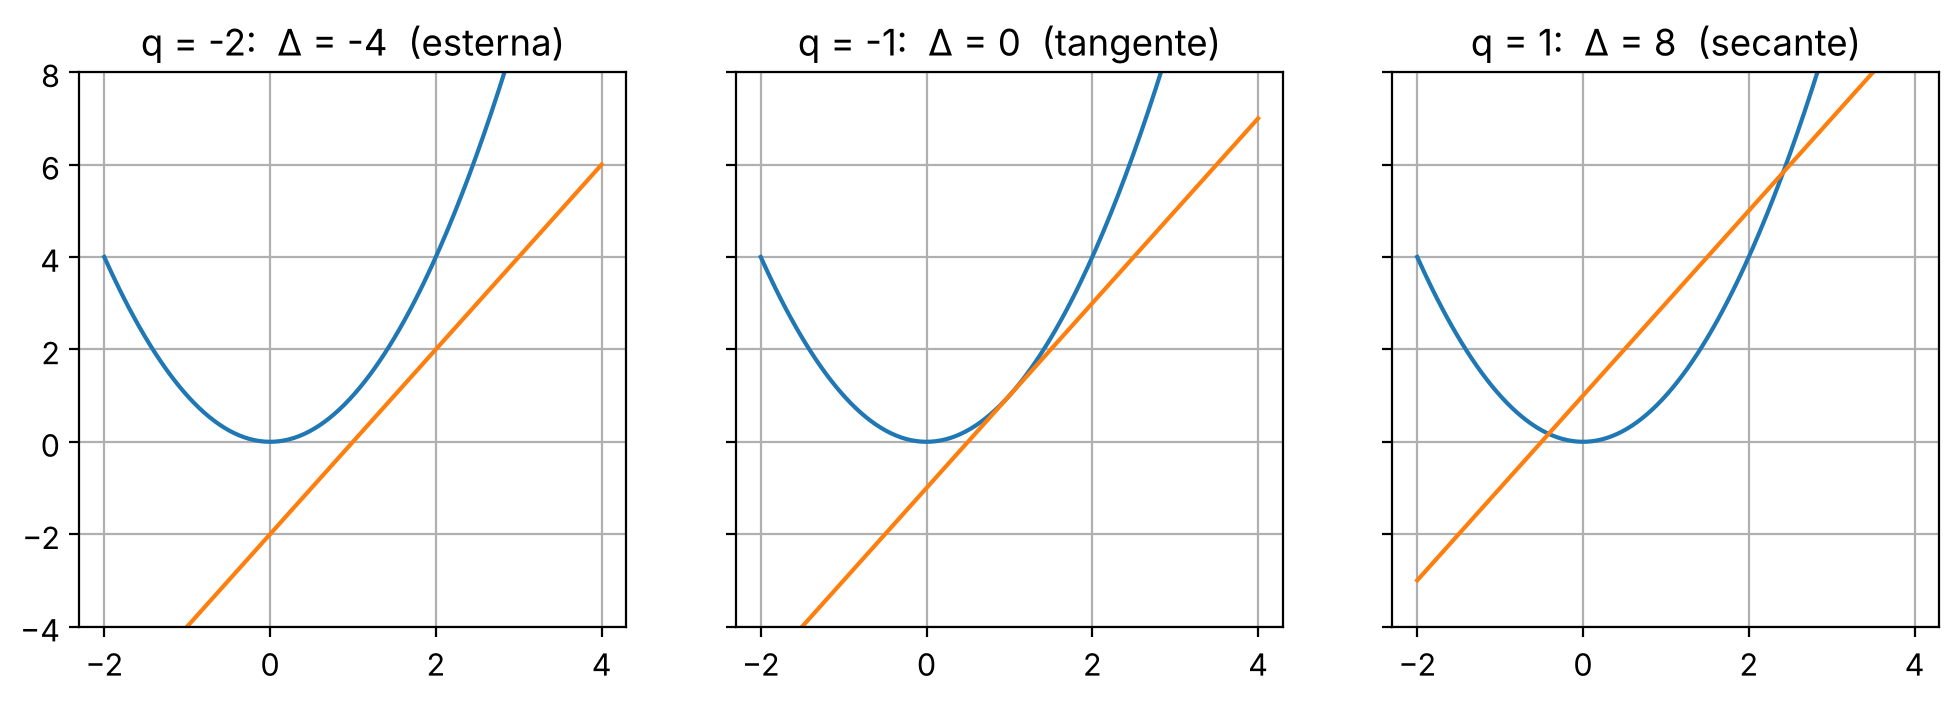

In [9]:
x = sp.symbols("x")
fig, assi = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
xs = np.linspace(-2, 4, 200)
for ax, q in zip(assi, (-2, -1, 1)):
    d = sp.discriminant(x**2 - (2*x + q), x)
    tipo = "esterna" if d < 0 else "tangente" if d == 0 else "secante"
    ax.plot(xs, xs**2)
    ax.plot(xs, 2*xs + q)
    ax.set_ylim(-4, 8)
    ax.set_title(f"q = {q}:  Δ = {d}  ({tipo})")
plt.show()

## 5. La circonferenza

Da $x^2 + y^2 + ax + by + c = 0$: centro $C\!\left(-\dfrac{a}{2}, -\dfrac{b}{2}\right)$ e raggio $r = \sqrt{\dfrac{a^2}{4} + \dfrac{b^2}{4} - c}$, reale se il radicando è positivo.

centro (2.0, -3.0)  raggio 4.0
distanza centro-retta = 2.12  <  r = 4.0  ->  retta secante


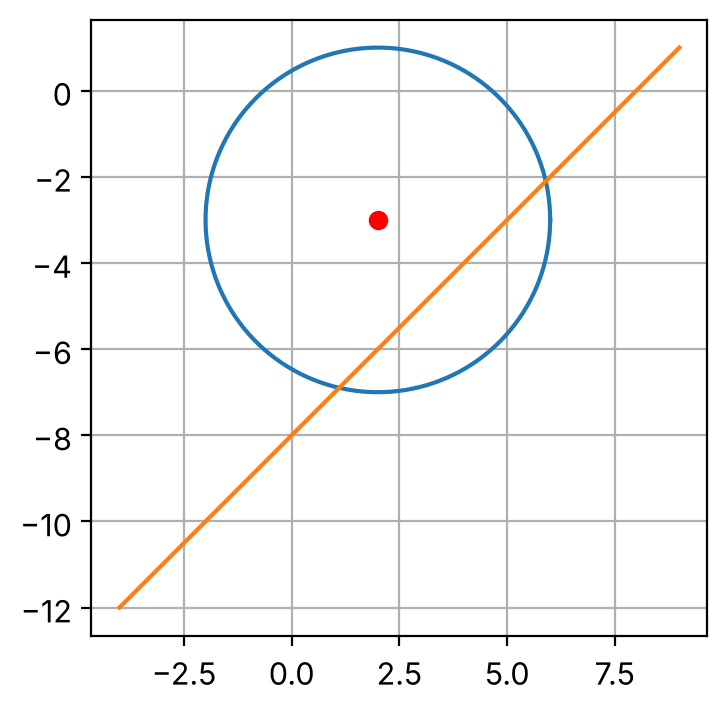

In [10]:
a, b, c = -4, 6, -3
radicando = a**2/4 + b**2/4 - c
centro = (-a/2, -b/2)
r = np.sqrt(radicando)
print("centro", centro, " raggio", r)

t = np.linspace(0, 2*np.pi, 300)
plt.plot(centro[0] + r*np.cos(t), centro[1] + r*np.sin(t))
plt.scatter(*centro, color="red")

# retta y = x - 8: confronto fra distanza dal centro e raggio
dist = abs(centro[0] - centro[1] - 8) / np.sqrt(2)
print(f"distanza centro-retta = {dist:.2f}  <  r = {r}  ->  retta secante")
xs = np.linspace(-4, 9, 100)
plt.plot(xs, xs - 8)
plt.gca().set_aspect("equal")
plt.show()

## 6. Goniometria

Sulla circonferenza goniometrica il punto associato all'angolo $\theta$ ha coordinate $(\cos\theta,\ \sin\theta)$. Il grafico di $y = \sin\theta$ si ottiene riportando l'ordinata del punto al variare di $\theta$.

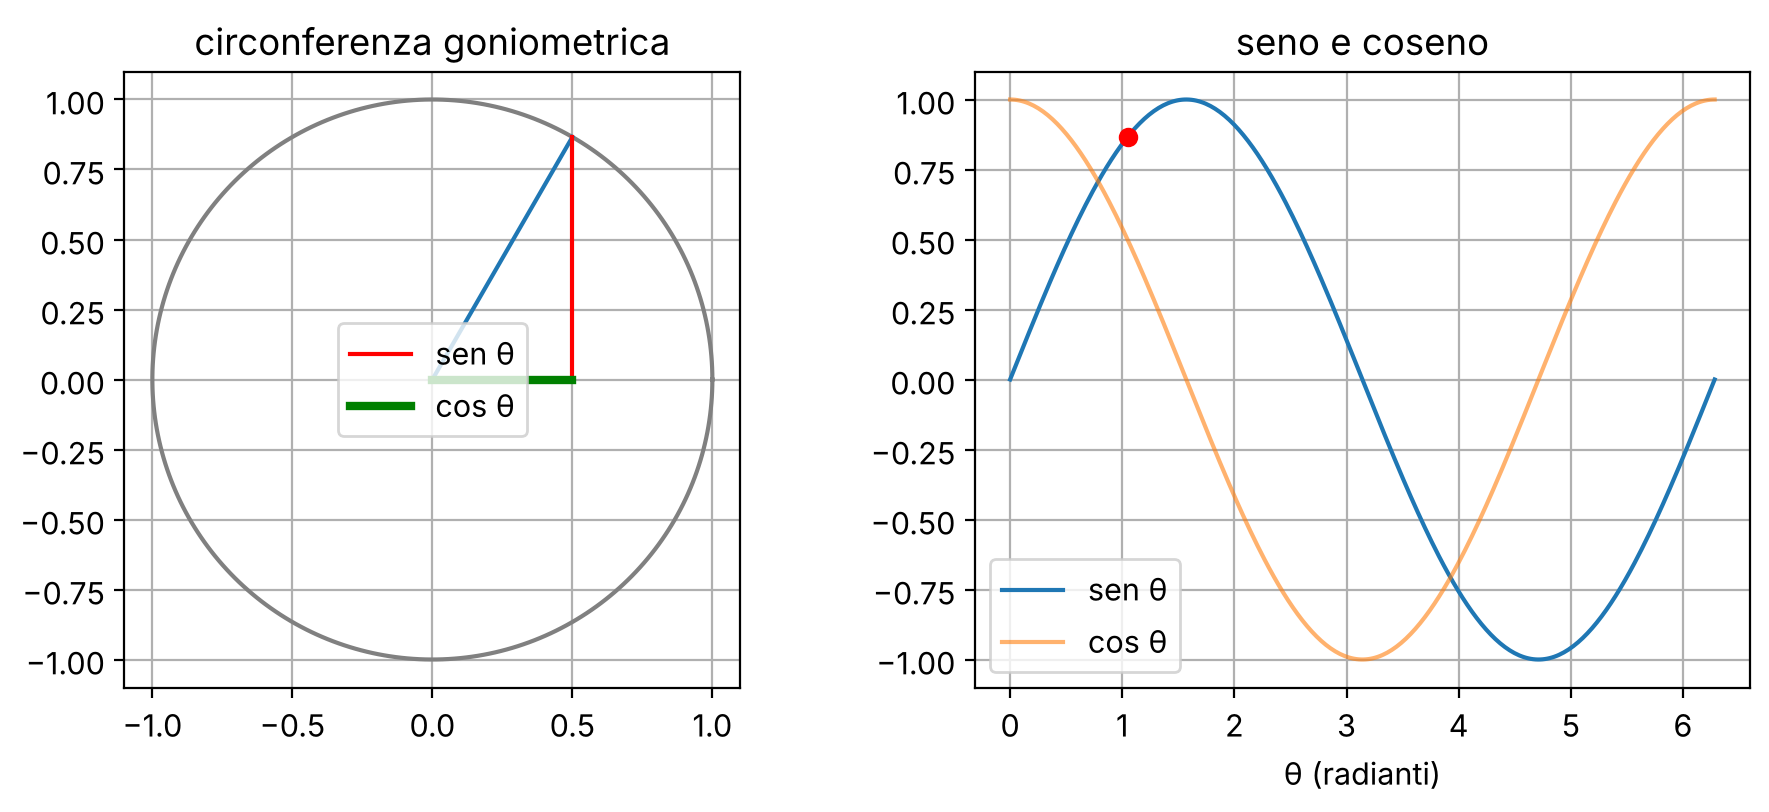

In [11]:
theta = np.deg2rad(60)
t = np.linspace(0, 2*np.pi, 300)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))

a1.plot(np.cos(t), np.sin(t), color="gray")
a1.plot([0, np.cos(theta)], [0, np.sin(theta)], color="tab:blue")
a1.plot([np.cos(theta)]*2, [0, np.sin(theta)], color="red", label="sen θ")
a1.plot([0, np.cos(theta)], [0, 0], color="green", linewidth=3, label="cos θ")
a1.set_aspect("equal"); a1.legend(); a1.set_title("circonferenza goniometrica")

a2.plot(t, np.sin(t), label="sen θ")
a2.plot(t, np.cos(t), label="cos θ", alpha=0.6)
a2.scatter([theta], [np.sin(theta)], color="red", zorder=3)
a2.legend(); a2.set_xlabel("θ (radianti)"); a2.set_title("seno e coseno")
plt.show()

Verifica numerica della relazione fondamentale $\sin^2\theta + \cos^2\theta = 1$ e soluzioni dell'equazione elementare $\sin x = \tfrac{1}{2}$ in $[0, 2\pi]$.

sen² + cos² = 1 su 1000 angoli casuali: True
Soluzioni: {pi/6, 5*pi/6}


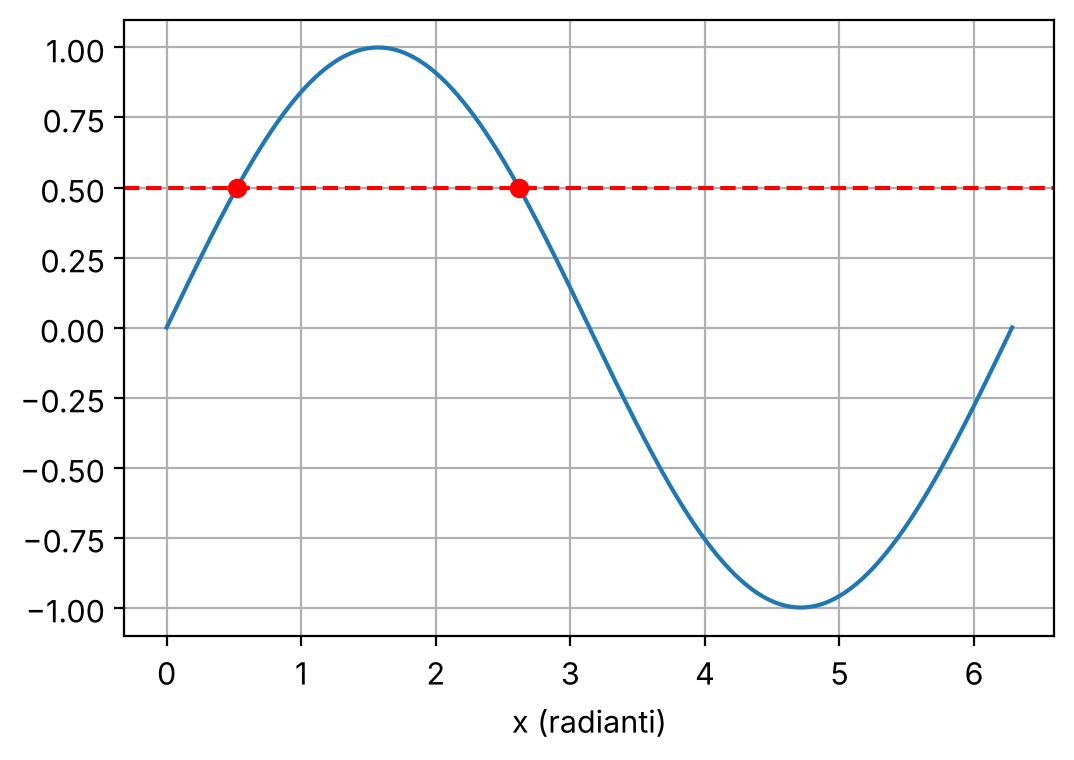

In [12]:
ang = np.random.default_rng(1).uniform(0, 2*np.pi, 1000)
print("sen² + cos² = 1 su 1000 angoli casuali:", np.allclose(np.sin(ang)**2 + np.cos(ang)**2, 1))

x = sp.symbols("x")
sol = sp.solveset(sp.sin(x) - sp.Rational(1, 2), x, sp.Interval(0, 2*sp.pi))
print("Soluzioni:", sol)

t = np.linspace(0, 2*np.pi, 300)
plt.plot(t, np.sin(t))
plt.axhline(0.5, color="red", linestyle="--")
plt.scatter([np.pi/6, 5*np.pi/6], [0.5, 0.5], color="red", zorder=3)
plt.xlabel("x (radianti)")
plt.show()

## 7. Trigonometria: risoluzione di un triangolo

Dati il lato $a = 7$ e gli angoli $\alpha = 40°$, $\beta = 65°$: il terzo angolo è $\gamma = 180° - \alpha - \beta$ e il teorema dei seni, $\dfrac{a}{\sin\alpha} = \dfrac{b}{\sin\beta} = \dfrac{c}{\sin\gamma}$, fornisce gli altri due lati.

gamma = 75.0°,  b = 9.870,  c = 10.519
teorema del coseno: True
area = 33.367


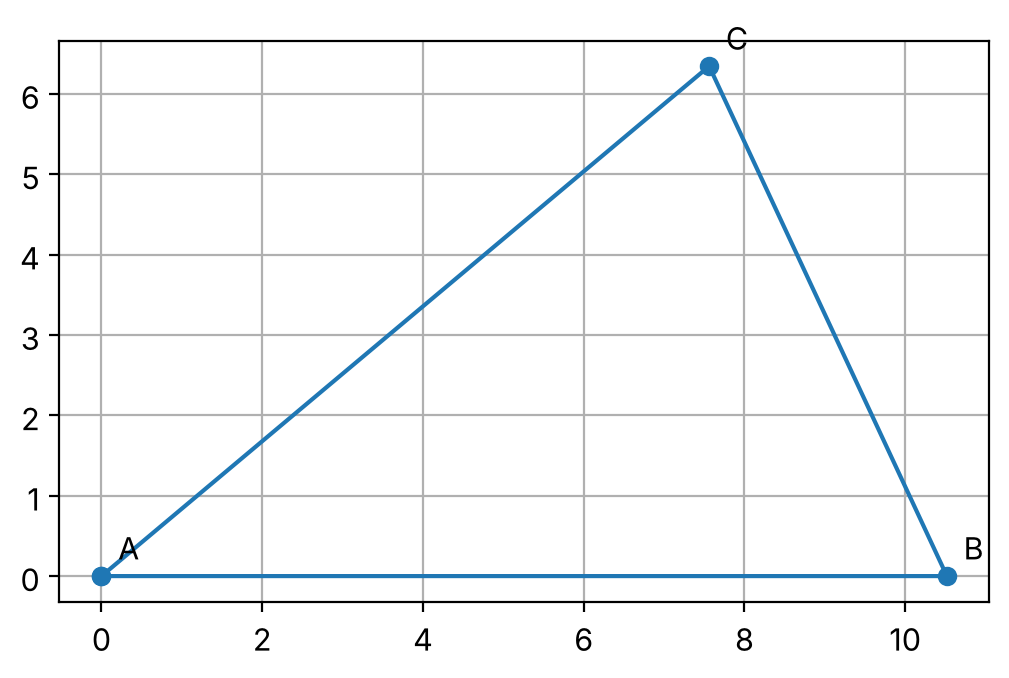

In [13]:
a_, al, be = 7, np.deg2rad(40), np.deg2rad(65)
ga = np.pi - al - be
b_ = a_ * np.sin(be) / np.sin(al)
c_ = a_ * np.sin(ga) / np.sin(al)
print(f"gamma = {np.rad2deg(ga):.1f}°,  b = {b_:.3f},  c = {c_:.3f}")

# controllo con il teorema del coseno e area con la formula trigonometrica
print("teorema del coseno:", np.isclose(a_**2, b_**2 + c_**2 - 2*b_*c_*np.cos(al)))
print(f"area = {0.5*b_*c_*np.sin(al):.3f}")

# A nell'origine, B sull'asse x, C determinato da b e dall'angolo in A
A = np.array([0, 0]); B = np.array([c_, 0]); C = np.array([b_*np.cos(al), b_*np.sin(al)])
tri = np.array([A, B, C, A])
plt.plot(tri[:, 0], tri[:, 1], "-o")
for nome, p in zip("ABC", (A, B, C)):
    plt.annotate(nome, p, textcoords="offset points", xytext=(6, 6))
plt.gca().set_aspect("equal")
plt.show()

## 8. Esponenziali e logaritmi

La funzione logaritmica è l'inversa di quella esponenziale con la stessa base: i grafici sono simmetrici rispetto alla retta $y = x$.

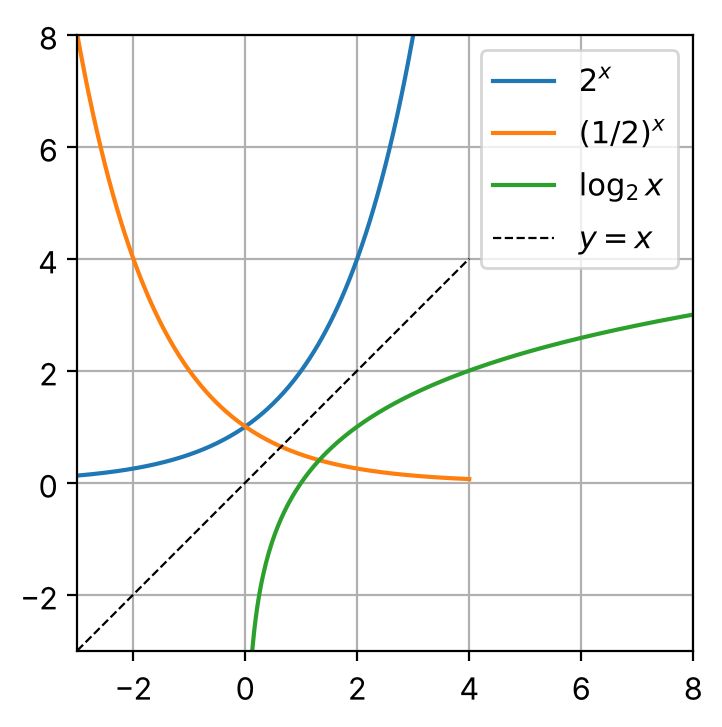

In [14]:
xs = np.linspace(-3, 4, 300)
xl = np.linspace(0.05, 8, 300)
plt.plot(xs, 2.0**xs, label="$2^x$")
plt.plot(xs, 0.5**xs, label="$(1/2)^x$")
plt.plot(xl, np.log2(xl), label="$\\log_2 x$")
plt.plot(xs, xs, "k--", linewidth=0.8, label="$y = x$")
plt.ylim(-3, 8); plt.xlim(-3, 8)
plt.gca().set_aspect("equal")
plt.legend()
plt.show()

Equazione esponenziale risolta con i logaritmi: $3^x = 20 \Rightarrow x = \log_3 20$.

In [15]:
x = sp.symbols("x")
sol = sp.solve(sp.Eq(3**x, 20), x)[0]
print(sol, "=", float(sol))
print("verifica:", 3**float(sol))

log(20)/log(3) = 2.726833027860842
verifica: 20.000000000000004


Modello di crescita: una popolazione cresce del 30% a ogni ora a partire da 100 individui. I dati (con una piccola variazione casuale) vengono approssimati con una curva esponenziale $P(t) = P_0\,r^t$; in scala logaritmica l'andamento esponenziale diventa una retta.

P0 = 106.2,  r = 1.288  (crescita del 28.8% a ora)
tempo di raddoppio = 2.74 ore


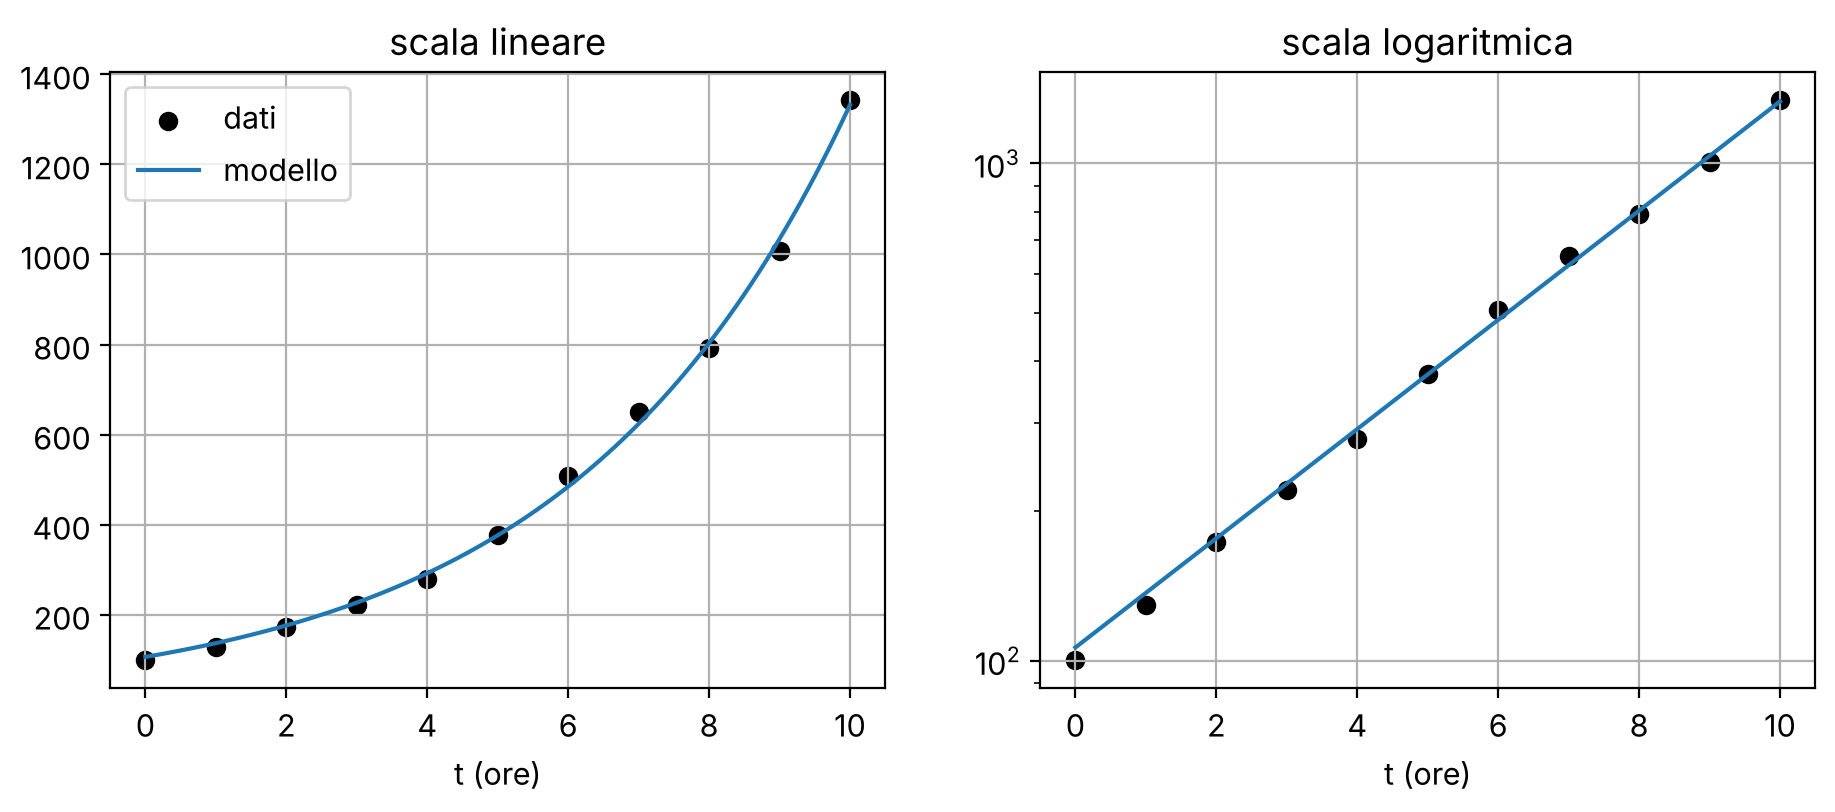

In [16]:
from scipy.optimize import curve_fit

rng = np.random.default_rng(0)
t = np.arange(0, 11)
P = 100 * 1.3**t * rng.normal(1, 0.04, t.size)

(P0, r), _ = curve_fit(lambda t, P0, r: P0 * r**t, t, P, p0=(100, 1.2))
print(f"P0 = {P0:.1f},  r = {r:.3f}  (crescita del {100*(r-1):.1f}% a ora)")
print(f"tempo di raddoppio = {np.log(2)/np.log(r):.2f} ore")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
tt = np.linspace(0, 10, 100)
for ax in (a1, a2):
    ax.scatter(t, P, color="black", label="dati")
    ax.plot(tt, P0 * r**tt, label="modello")
a1.set_title("scala lineare"); a1.legend()
a2.set_yscale("log"); a2.set_title("scala logaritmica")
for ax in (a1, a2):
    ax.set_xlabel("t (ore)")
plt.show()

## 9. Verificare una risposta con il calcolo simbolico

Una risposta ricevuta da un assistente AI, o ricavata a mano, si controlla con un metodo indipendente. Due espressioni sono equivalenti se la loro differenza si semplifica a zero.

In [17]:
x = sp.symbols("x")

def equivalenti(e1, e2):
    return sp.simplify(sp.sympify(e1) - sp.sympify(e2)) == 0

# espressione da semplificare: (x + 1)^2 - (x - 1)^2
originale = "(x + 1)**2 - (x - 1)**2"
print("risposta 4*x :", equivalenti(originale, "4*x"))
print("risposta 4   :", equivalenti(originale, "4"))

risposta 4*x : True
risposta 4   : False


## 10. Esplorazione interattiva (facoltativa)

Con la libreria `ipywidgets` un cursore modifica un parametro e il grafico si aggiorna. La cella funziona in Jupyter, non nell'anteprima statica del file.

In [18]:
try:
    from ipywidgets import interact, FloatSlider

    @interact(m=FloatSlider(min=-3, max=3, step=0.1, value=1),
              q=FloatSlider(min=-4, max=4, step=0.5, value=0))
    def retta(m, q):
        xs = np.linspace(-5, 5, 100)
        plt.plot(xs, m*xs + q)
        plt.xlim(-5, 5); plt.ylim(-8, 8)
        plt.title(f"y = {m:.1f}x + {q:.1f}")
        plt.show()
except ImportError:
    print("ipywidgets non installato: pip install ipywidgets")

interactive(children=(FloatSlider(value=1.0, description='m', max=3.0, min=-3.0), FloatSlider(value=0.0, descr…